# COVID-19 impact on Singapore General Hospital (SGH)

**Question:** Based on the available data, what impact did COVID-19 have on SGH during 2020–2021?

**Data:** `119SMU-XLS-ENG.xlsx` (case spreadsheet), calendar years 2018–2022.

**What this notebook reports.** Only figures taken directly from the spreadsheet, plus simple arithmetic on them (totals, differences and percentage changes). No estimates, no assumed values, and no conclusions about causes.

1. Total patient days per year
2. Average beds in service per year, and the change by specialty
3. Patient days by specialty
4. Infectious Diseases patient days per month

> The spreadsheet uses **calendar years**. The case paper's Exhibit 3 uses **financial years ending in March**, so the two sources show different figures.

## 1. Setup

Install the libraries once if needed (`pip install pandas openpyxl matplotlib`).
Put the Excel file in the same folder as this notebook, or upload it if you are using Google Colab, and set `FILE` to its name.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

FILE = "119SMU-XLS-ENG.xlsx"      # <-- change if your file has a different name
OUT = Path("covid_output")
OUT.mkdir(exist_ok=True)

YEARS = [2018, 2019, 2020, 2021, 2022]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

DARK, TEAL, ORANGE, GREY = "#10303B", "#1C7C74", "#D9682B", "#9DB8B4"
plt.rcParams.update({"axes.spines.top": False, "font.size": 11})
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Load patient days

The sheet **"Patient Days by Speciality"** is laid out like a report:
- each year is 12 month columns plus a Total column (13 columns per year), starting at column C;
- the specialty name appears only on the first row of each block;
- there are "… Total" and "Grand Total" rows.

So we read it row by row, **carry the specialty name down**, **skip the total rows**, and build a tidy table with one row per specialty, class, year and month.

In [2]:
raw = pd.read_excel(FILE, sheet_name="Patient Days by Speciality",
                    header=None, skiprows=4)

rows, specialty = [], None
for _, r in raw.iterrows():
    if isinstance(r[0], str):
        if "Total" in r[0]:              # skip subtotal and grand total rows
            continue
        specialty = r[0].strip()         # remember the current specialty
    if specialty is None or not isinstance(r[1], str):
        continue
    for yi, year in enumerate(YEARS):
        for mi in range(12):
            v = r[2 + yi * 13 + mi]      # column position of that year and month
            rows.append([specialty, r[1].strip(), year, mi + 1,
                         0 if pd.isna(v) else float(v)])

pdays = pd.DataFrame(rows, columns=["Specialty", "Class", "Year", "Month", "PatientDays"])
pdays.head()

,Specialty,Class,Year,Month,PatientDays
0,Burns,Non-Resident/Foreigner,2018,1,34.00
1,Burns,Non-Resident/Foreigner,2018,2,41.00
2,Burns,Non-Resident/Foreigner,2018,3,101.00
3,Burns,Non-Resident/Foreigner,2018,4,120.00
4,Burns,Non-Resident/Foreigner,2018,5,76.00


**Check:** the tidy table must add up to the sheet's own Grand Total of 2,525,430 patient days. If it does, nothing was lost or double-counted.

In [3]:
total = pdays.PatientDays.sum()
print(f"Total patient days: {total:,.0f}")
assert round(total) == 2_525_430, "Total does not match the sheet's Grand Total"
print("Matches the sheet's Grand Total")

Total patient days: 2,525,430
Matches the sheet's Grand Total


## 3. Load beds in service

The sheet **"Monthly Ave Beds Available"** has a table on the right (columns K–Q) with the **average licensed beds in service per specialty per year**, as reported in the spreadsheet.

The only change made is spelling: the beds sheet writes "General surgery" and the patient-days sheet writes "General Surgery", so the name is made consistent.

In [4]:
braw = pd.read_excel(FILE, sheet_name="Monthly Ave Beds Available",
                     header=None, skiprows=2)
beds = braw.iloc[:, 10:17].dropna(subset=[10])
beds.columns = ["Specialty", "Code"] + YEARS
beds = beds[beds.Specialty != "Grand Total"].copy()
beds["Specialty"] = beds.Specialty.str.strip().replace({"General surgery": "General Surgery"})
beds = beds.set_index("Specialty")[YEARS].astype(float)
beds.round(1)

,2018,2019,2020,2021,2022
Specialty,,,,,
Burns,32.40,29.00,29.00,29.80,28.10
Colorectal Surgery,61.00,61.00,60.20,44.80,53.80
Internal Medicine,331.00,333.00,389.20,432.20,370.60
Endocrinology,15.00,15.00,12.80,15.00,15.00
Otorhinolaryngology,33.00,33.00,33.00,33.00,32.80
Ophthalmology,10.00,10.00,8.30,10.00,10.00
Gastroenterology,38.80,39.20,39.20,38.00,40.00
Geriatric Medicine,25.00,25.00,25.00,25.00,25.00
Gynaecology,23.00,23.00,23.00,25.20,22.80


## 4. Patient days and average beds in service per year

- **Patient days**: sum of all specialties and classes for the year
- **Average beds in service**: sum of all specialties (the sheet's own Grand Total row)
- **% change** = this year ÷ previous year − 1

In [5]:
yearly = pd.DataFrame({
    "Patient days": pdays.groupby("Year").PatientDays.sum(),
    "Avg beds in service": beds.sum(),
})
yearly["Patient days change %"] = yearly["Patient days"].pct_change() * 100
yearly["Beds change %"] = yearly["Avg beds in service"].pct_change() * 100
yearly

,Patient days,Avg beds in service,Patient days change %,Beds change %
2018,"488,269.00","1,583.90",NaN,NaN
2019,"488,531.00","1,577.83",0.05,-0.38
2020,"484,569.00","1,731.78",-0.81,9.76
2021,"521,756.00","1,718.58",7.67,-0.76
2022,"542,305.00","1,713.83",3.94,-0.28


In [6]:
y20, y21 = yearly.loc[2020], yearly.loc[2021]
print(f"2020 vs 2019: patient days {y20['Patient days change %']:+.2f}%, "
      f"average beds in service {y20['Beds change %']:+.2f}%")
print(f"2021 vs 2020: patient days {y21['Patient days change %']:+.2f}%, "
      f"average beds in service {y21['Beds change %']:+.2f}%")

2020 vs 2019: patient days -0.81%, average beds in service +9.76%
2021 vs 2020: patient days +7.67%, average beds in service -0.76%


## 5. Change in average beds in service by specialty, 2019 → 2020

Difference = 2020 value − 2019 value, for each specialty. These are changes in **average beds in service** as reported, not counts of beds built or purchased.

In [7]:
bed_change = (beds[2020] - beds[2019]).sort_values(ascending=False)
total_added = beds[2020].sum() - beds[2019].sum()
id_added = bed_change["Infectious Diseases"]
id_share = id_added / total_added * 100

print(f"Net change in average beds in service, 2019 -> 2020: {total_added:+.1f}")
print(f"Infectious Diseases: {id_added:+.1f} ({id_share:.0f}% of the net change)")
bed_change.round(1).to_frame("Change 2019-2020")

Net change in average beds in service, 2019 -> 2020: +154.0
Infectious Diseases: +111.1 (72% of the net change)


,Change 2019-2020
Specialty,
Infectious Diseases,111.10
Internal Medicine,56.20
Rehabilitation Medicine,23.80
General Surgery,17.50
Respiratory Medicine,16.90
Neurology,1.20
Gastroenterology,0.10
Obstetrics,0.10
Otorhinolaryngology,0.00


## 6. Patient days by specialty, 2019 and 2020

Patient days for each specialty and the % change. The patient-day columns are shown next to the percentage because a large percentage in a small specialty can be a small number of patient days.

In [8]:
spec = pdays.pivot_table(index="Specialty", columns="Year",
                         values="PatientDays", aggfunc="sum")
spec["Change 2019-2020 %"] = (spec[2020] / spec[2019] - 1) * 100
spec[[2019, 2020, "Change 2019-2020 %"]].sort_values("Change 2019-2020 %").round(1)

Year,2019,2020,Change 2019-2020 %
Specialty,,,
Burns,"1,955.00","1,190.00",-39.10
Psychiatric Medicine,"2,778.00","1,800.00",-35.20
Ophthalmology,"2,612.00","2,011.00",-23.00
Nuclear Medicine,449.00,362.00,-19.40
Obstetrics,"6,662.00","5,424.00",-18.60
Rehabilitation Medicine,"16,220.00","13,550.00",-16.50
Orthopaedic Surgery,"43,835.00","36,906.00",-15.80
Urology,"8,245.00","6,945.00",-15.80
Geriatric Medicine,"3,742.00","3,187.00",-14.80


## 7. Infectious Diseases patient days per month

In [9]:
id_monthly = (pdays[pdays.Specialty == "Infectious Diseases"]
              .groupby(["Year", "Month"]).PatientDays.sum().reset_index())
id_monthly["Label"] = [f"{MONTHS[m - 1]} {str(y)[2:]}"
                       for y, m in zip(id_monthly.Year, id_monthly.Month)]
id_monthly.sort_values("PatientDays", ascending=False).head(6)

,Year,Month,PatientDays,Label
45,2021,10,"5,135.00",Oct 21
28,2020,5,"3,914.00",May 20
46,2021,11,"3,884.00",Nov 21
27,2020,4,"3,805.00",Apr 20
44,2021,9,"2,851.00",Sep 21
49,2022,2,"1,623.00",Feb 22


## 8. Charts

### Chart A: patient days and average beds in service, 2018–2022
Columns are patient days (left axis, 2020 highlighted). The line is average beds in service (right axis). Both axes start above zero so the changes are visible; the note on the chart says so.

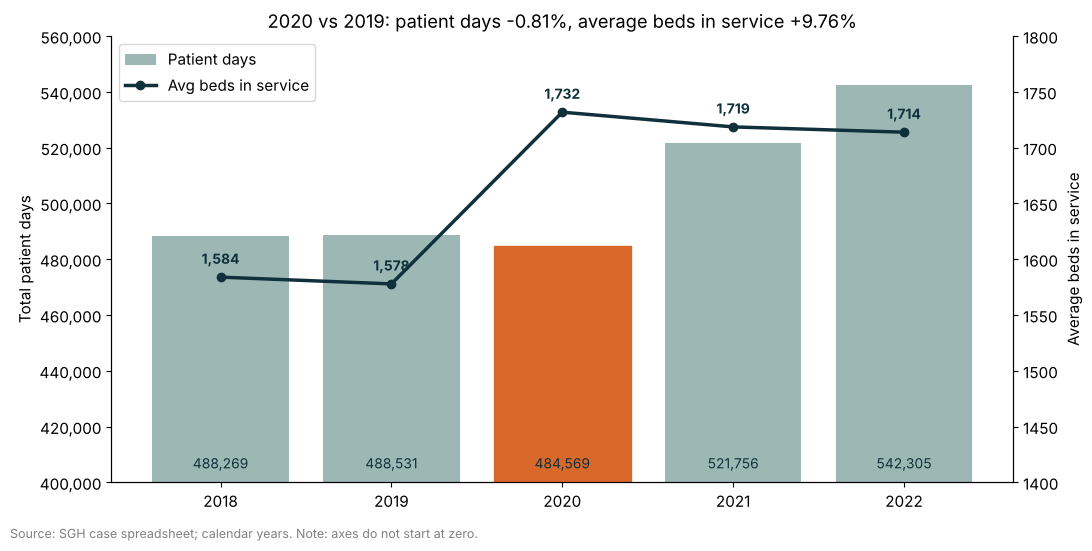

In [10]:
x = [str(y) for y in YEARS]
fig, ax1 = plt.subplots(figsize=(11, 5.5))
bars = ax1.bar(x, yearly["Patient days"], color=GREY, label="Patient days")
bars[2].set_color(ORANGE)
ax1.set_ylabel("Total patient days")
ax1.set_ylim(400_000, 560_000)
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
for b, v in zip(bars, yearly["Patient days"]):
    ax1.text(b.get_x() + b.get_width() / 2, 405_000, f"{v:,.0f}",
             ha="center", fontsize=10, color=DARK)

ax2 = ax1.twinx()
ax2.plot(x, yearly["Avg beds in service"], color=DARK, marker="o", lw=2.5,
         label="Avg beds in service")
ax2.set_ylabel("Average beds in service")
ax2.set_ylim(1_400, 1_800)
for xi, v in zip(x, yearly["Avg beds in service"]):
    ax2.text(xi, v + 12, f"{v:,.0f}", ha="center", color=DARK, fontsize=10,
             fontweight="bold")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title(f"2020 vs 2019: patient days {y20['Patient days change %']:+.2f}%, "
              f"average beds in service {y20['Beds change %']:+.2f}%")
fig.text(0.01, 0.01, "Source: SGH case spreadsheet; calendar years. "
         "Note: axes do not start at zero.", fontsize=9, color="grey")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(OUT / "A_combo_patient_days_vs_beds.png", dpi=200)
plt.show()

### Chart F: change in average beds in service by specialty, 2019 → 2020
Every specialty is shown.

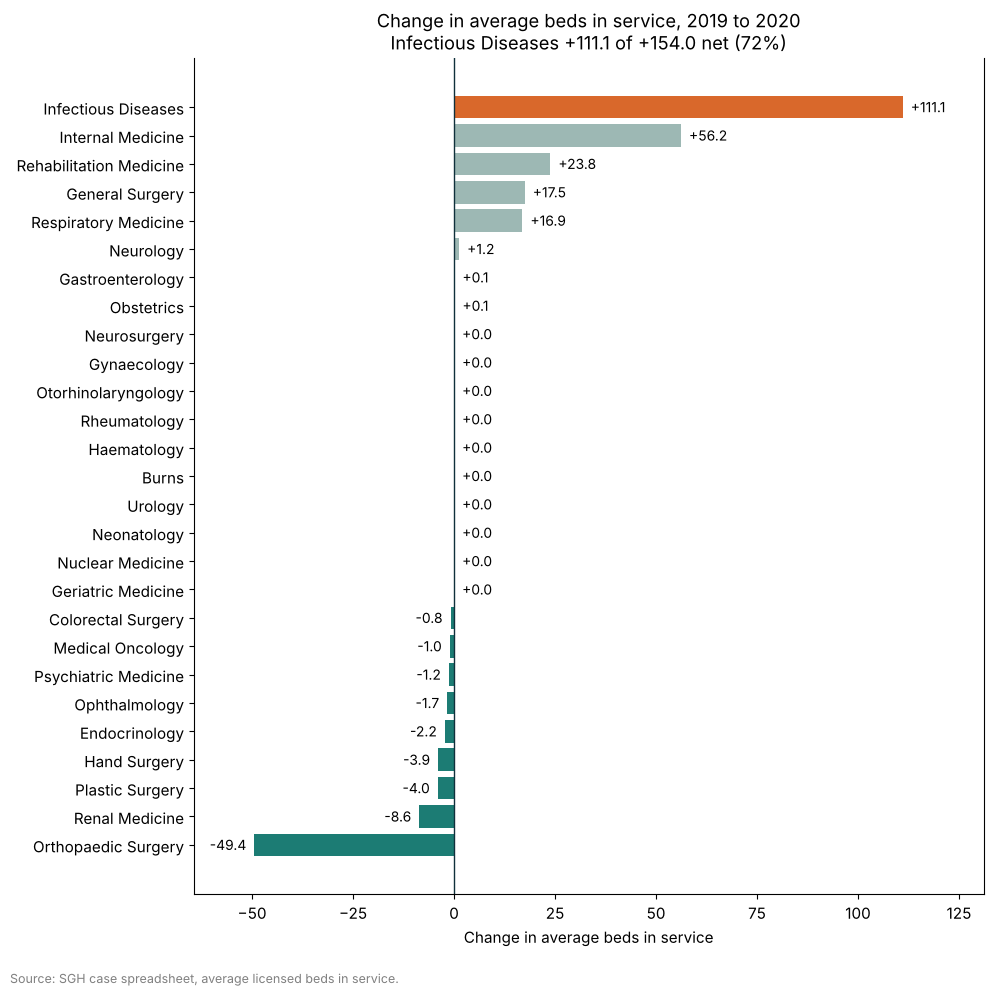

In [11]:
chg = bed_change.sort_values()
fig, ax = plt.subplots(figsize=(10, 10))
colors = [ORANGE if s == "Infectious Diseases" else (GREY if v > 0 else TEAL)
          for s, v in chg.items()]
ax.barh(chg.index, chg.values, color=colors)
ax.axvline(0, color=DARK, lw=1)
for i, v in enumerate(chg.values):
    ax.text(v + (2 if v >= 0 else -2), i, f"{v:+.1f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=10)
ax.set_xlim(chg.min() - 15, chg.max() + 20)
ax.set_xlabel("Change in average beds in service")
ax.set_title(f"Change in average beds in service, 2019 to 2020\n"
             f"Infectious Diseases {id_added:+.1f} of {total_added:+.1f} net ({id_share:.0f}%)")
fig.text(0.01, 0.01, "Source: SGH case spreadsheet, average licensed beds in service.",
         fontsize=9, color="grey")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(OUT / "F_bed_change_by_specialty.png", dpi=200)
plt.show()

### Chart E: Infectious Diseases patient days per month (2018–2022)

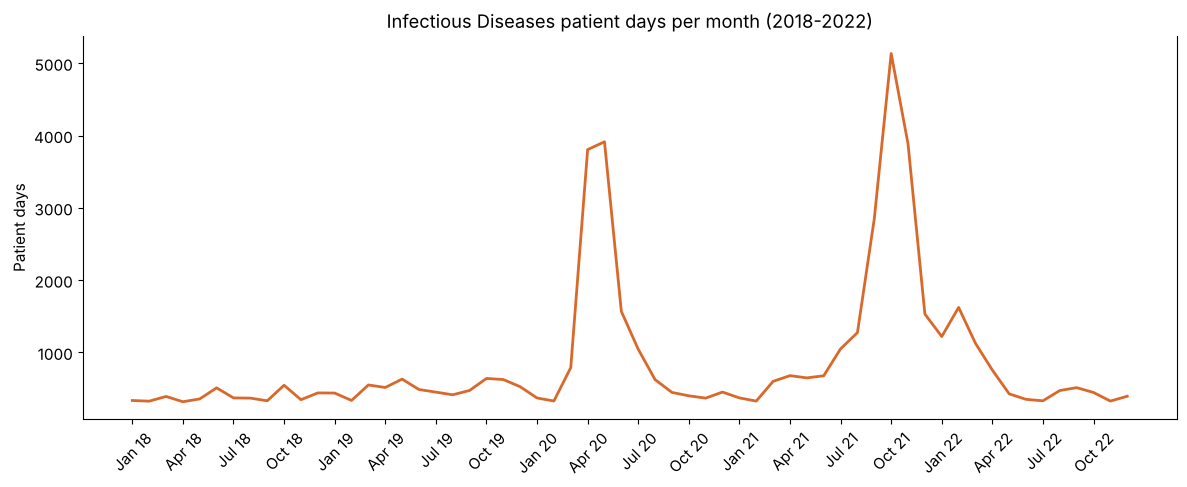

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(id_monthly.Label, id_monthly.PatientDays, color=ORANGE, lw=2)
ax.set_xticks(range(0, 60, 3))
ax.set_xticklabels(id_monthly.Label[::3], rotation=45)
ax.set_ylabel("Patient days")
ax.set_title("Infectious Diseases patient days per month (2018-2022)")
plt.tight_layout()
plt.savefig(OUT / "E_infectious_diseases_monthly.png", dpi=200)
plt.show()

## 9. Save all tables to Excel

In [13]:
with pd.ExcelWriter(OUT / "covid_impact_tables.xlsx") as xw:
    yearly.round(2).to_excel(xw, sheet_name="Impact 1+2 yearly")
    bed_change.round(1).to_frame("Change 2019-2020").to_excel(xw, sheet_name="Bed change by specialty")
    spec.round(1).to_excel(xw, sheet_name="Specialty change")
    id_monthly.to_excel(xw, sheet_name="ID monthly", index=False)
print(f"Charts and tables saved in: {OUT.resolve()}")

Charts and tables saved in: /home/claude/sgh_analysis/covid_output


## 10. Findings (from the spreadsheet only)

1. **Patient days:** 488,531 in 2019, 484,569 in 2020 (**−0.81%**) and 521,756 in 2021 (**+7.67%**).
2. **Average beds in service:** 1,577.83 in 2019, 1,731.78 in 2020 (**+9.76%**) and 1,718.58 in 2021 (**−0.76%**).
3. **Change by specialty, 2019 → 2020:** average beds in service rose by **154.0** overall. Infectious Diseases rose by **111.1**, which is **72%** of the net change. Orthopaedic Surgery fell by **49.4**.
4. **In 2020**, patient days decreased while average beds in service increased.

**What the spreadsheet does not show:** it does not identify COVID-19 patients or COVID-19 beds, the reasons for any change in patient days, or official bed occupancy rates. Statements about those need a source such as the case paper.

*Source: SGH case spreadsheet (119SMU-XLS-ENG.xlsx), calendar years.*